# Helsinki: nearest amenities and reachable amenities per mode

Third notebook of the Helsinki pipeline. `02.1` built the origin lattice and
the hexagon-to-hexagon cost matrices, `02.2` the amenity layer with its
two-level taxonomy. This notebook routes every inhabited hexagon to every
amenity point by four modes and derives two measures that need no behavioural
parameter:

- the **time to the nearest amenity** of each class and category, and the
  15-minute score it implies (how many categories a household reaches within
  the budget);
- the **amenities reachable** per category within 10, 20 and 30 minutes.

Both are computed with the same budget for every mode, so the modes are
compared on supply alone.

| Step | Output |
|---|---|
| 1. Travel times to amenities | `amenities/<mode>/`, streamed Parquet matrices |
| 2. Nearest amenity | `nearest_amenity.parquet`, hexagon by class by mode |
| 3. Fifteen-minute score | `fifteen_minute_score.parquet`, hexagon by mode |
| 4. Reachable amenities | `reachable_amenities.parquet`, hexagon by category by budget by mode |
| 5. Figures | Summary per mode, maps |

In [1]:
import json
import time
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, ListedColormap
import numpy as np
import pandas as pd

from cafein import StreetNetwork, TransportNetwork, TravelTimeMatrix
from cafein.accessibility import Accessibility
from cafein._streaming import read_shards

## Parameters

The car options repeat `02.1` (rush-hour intersection delays, parking search
at the destination) and the transit departure is the same Tuesday morning.
Street searches stop at the cutoff; a transit journey has no cutoff in the
engine, so the same ceiling is applied afterwards to every mode.

In [2]:
CITY = "helsinki"
RESULTS = Path("/scratch/project_2010423/carbon-advantage") / CITY
ARTIFACTS = Path("../networks")
METRIC_CRS = "EPSG:3067"

PARAMETERS = {
    "city": CITY,
    "departure": "2026-09-08 08:30",
    "modes": ["walk", "bicycle", "e_bike", "transit", "car"],
    # Minutes beyond which an amenity counts as unreachable, every mode.
    "cutoff_min": 60,
    # One-way time tolerances of the active modes, applied only when the switch
    # is on. Walking: Yang & Diez-Roux (2012) report a median walking trip of
    # 10 min and 18 % of trips over a mile, so 30 min bounds nearly all
    # utilitarian walks. Bicycle: 30 min at 15.3 km/h is 7.7 km, close to the
    # 7.5 km short-distance threshold of the Dutch cycling literature (Heinen,
    # van Wee & Maat 2010). E-bike: 45 min at 17.4 km/h is 13 km, above the
    # 9.4 km trips e-bike users report against 4.8 km for cyclists (Castro et
    # al. 2019, PASTA); the tolerance is kept in time, as before the speeds of
    # the two modes were separated in cafein 0.30.
    "active_mode_cutoffs_min": {"walk": 30, "bicycle": 30, "e_bike": 45},
    "apply_active_cutoffs": False,
    # The budgets of the cumulative measure and of the score.
    "budgets_min": [10, 20, 30],
    "score_budget_min": 15,
    "car": {"intersection_delays": True, "profile": "rush", "parking": True},
    # Riding speeds of the cycling modes in km/h, passed to every street query.
    # cafein's defaults since 0.30: the mean trip speeds of conventional
    # bicycles and pedelecs in Schleinitz et al. (2017). The bicycle is also
    # slowed uphill and credited downhill by the slope model; the e-bike is not.
    "street_speeds_kmph": {"bicycle": 15.3, "e_bike": 17.4},
    "max_rides": 8,
}
(RESULTS / "nearest_parameters.json").write_text(json.dumps(PARAMETERS, indent=2))

lattice = gpd.read_file(RESULTS / "lattice.gpkg")
pois = gpd.read_file(RESULTS / "pois.gpkg")
taxonomy = json.loads((RESULTS / "poi_taxonomy.json").read_text())["taxonomy"]
CLASSES = list(taxonomy)
CATEGORIES = list(dict.fromkeys(rule["category"] for rule in taxonomy.values()))
MODES = PARAMETERS["modes"]

# One routed point per OSM feature; the class memberships join back later.
pois["point_id"] = pois["osm_type"].str[0] + pois["osm_id"].astype(str)
points = pois.drop_duplicates("point_id")[["point_id", "geometry"]].rename(columns={"point_id": "id"})
points = points.reset_index(drop=True)
membership = pois[["point_id", "poi_class", "category"]].rename(columns={"point_id": "to_id"})
print(f"{len(lattice):,} hexagons, {len(points):,} amenity points, {len(membership):,} class memberships")

1,105 hexagons, 30,989 amenity points, 31,083 class memberships


## 1. Travel times to every amenity

One lean travel-time matrix per mode from the hexagon centroids to the
amenity points, streamed to Parquet with the resume manifest, exactly as the
cost matrices in `02.1`. Walking and cycling are door to door on the street
artifact; the car adds the rush-hour delays and the parking search; transit is
door to door at the common departure.

In [3]:
def matrix_complete(path):
    '''True when a streamed matrix directory has every shard completed.'''
    manifest = Path(path) / "manifest.json"
    if not manifest.is_file():
        return False
    shards = json.loads(manifest.read_text())["shards"]
    return bool(shards) and all(shard["completed"] for shard in shards)


streets = StreetNetwork.load(ARTIFACTS / "helsinki-streets.cafein")
transit = TransportNetwork.load(ARTIFACTS / "helsinki-region.cafein")

QUERIES = {
    "walk": dict(network=streets, transport_mode="walk"),
    "bicycle": dict(network=streets, transport_mode="bicycle", speeds={"bicycle": PARAMETERS["street_speeds_kmph"]["bicycle"]}),
    "e_bike": dict(network=streets, transport_mode="e_bike", speeds={"e_bike": PARAMETERS["street_speeds_kmph"]["e_bike"]}),
    "car": dict(network=streets, transport_mode="car", **PARAMETERS["car"]),
    "transit": dict(network=transit, departure=PARAMETERS["departure"], max_rides=PARAMETERS["max_rides"]),
}

for mode in MODES:
    output = RESULTS / "amenities" / mode
    if matrix_complete(output):
        print(f"{mode:8} complete -> {output}")
        continue
    query = dict(QUERIES[mode])
    network = query.pop("network")
    if "transport_mode" in query:
        query["max_street_time"] = PARAMETERS["cutoff_min"]
    started = time.time()
    TravelTimeMatrix.to_parquet(
        network, lattice, points,
        output_time_units="seconds",
        output=output,
        resume=output.exists(),
        **query,
    )
    print(f"{mode:8} {time.time() - started:7.0f} s -> {output}")

loading the network:   0%|          | 0/2 [00:02<?, ?it/s]

street matrix:  25%|##5       | 125/500 [00:02<00:06, 62.31it/s]

walk           5 s -> /scratch/project_2010423/carbon-advantage/helsinki/amenities/walk


bicycle        4 s -> /scratch/project_2010423/carbon-advantage/helsinki/amenities/bicycle


e_bike         5 s -> /scratch/project_2010423/carbon-advantage/helsinki/amenities/e_bike


travel_time_matrix: 100%|##########| 500/500 [00:02<00:00, 249.53it/s]

travel_time_matrix: 100%|##########| 500/500 [00:02<00:00, 249.53it/s]

travel_time_matrix: 100%|##########| 105/105 [00:02<00:00, 52.40it/s]

transit       71 s -> /scratch/project_2010423/carbon-advantage/helsinki/amenities/transit


/tmp/marinflo/2640876/ipykernel_958037/2127182915.py:31: UserWarning: 2 destination point(s) are off the streets the car profile can use and unreachable (n1431369312, w96810517)
  TravelTimeMatrix.to_parquet(


car            7 s -> /scratch/project_2010423/carbon-advantage/helsinki/amenities/car


## 2. Nearest amenity per class

For every hexagon, mode and class, the travel time to the closest amenity of
that class. A class with no amenity within the cutoff is kept as missing, so
that the share of hexagons it concerns stays visible. The category level is
the closest amenity of any class in the category.

In [4]:
CUTOFF_S = PARAMETERS["cutoff_min"] * 60
MODE_CUTOFF_S = {mode: PARAMETERS["cutoff_min"] * 60 for mode in MODES}
if PARAMETERS["apply_active_cutoffs"]:
    MODE_CUTOFF_S.update({mode: minutes * 60 for mode, minutes in PARAMETERS["active_mode_cutoffs_min"].items()})
grid = pd.MultiIndex.from_product([lattice["id"], MODES, CLASSES], names=["id", "mode", "poi_class"])

nearest_parts = []
for mode in MODES:
    matrix = read_shards(RESULTS / "amenities" / mode)
    matrix = matrix.loc[matrix["travel_time"] <= MODE_CUTOFF_S[mode]]
    with_class = matrix.merge(membership, on="to_id", how="inner")
    nearest_parts.append(
        with_class.groupby(["from_id", "poi_class"], observed=True)["travel_time"].min()
        .rename("nearest_s").reset_index().rename(columns={"from_id": "id"}).assign(mode=mode)
    )
nearest = (
    pd.concat(nearest_parts, ignore_index=True)
    .set_index(["id", "mode", "poi_class"])["nearest_s"].reindex(grid).reset_index()
)
nearest["nearest_min"] = nearest["nearest_s"] / 60
nearest["category"] = nearest["poi_class"].map({name: rule["category"] for name, rule in taxonomy.items()})
nearest["mode"] = pd.Categorical(nearest["mode"], categories=MODES)
nearest["poi_class"] = pd.Categorical(nearest["poi_class"], categories=CLASSES)
nearest["category"] = pd.Categorical(nearest["category"], categories=CATEGORIES)
nearest = nearest[["id", "mode", "category", "poi_class", "nearest_min"]]
nearest.to_parquet(RESULTS / "nearest_amenity.parquet", index=False)

nearest_category = (
    nearest.groupby(["id", "mode", "category"], observed=True)["nearest_min"].min().reset_index()
)
print(f"{len(nearest):,} rows; share of (hexagon, class) pairs with no amenity within the cutoff:")
nearest.groupby("mode", observed=True)["nearest_min"].apply(lambda s: s.isna().mean()).round(3)

337,025 rows; share of (hexagon, class) pairs with no amenity within the cutoff:


mode
walk       0.306
bicycle    0.027
e_bike     0.019
transit    0.082
car        0.012
Name: nearest_min, dtype: float64

## 3. Fifteen-minute score

Per hexagon and mode, the number of categories (and classes) whose nearest
amenity is within 15 minutes. The same budget is used for every mode, so the
score compares what each mode delivers, not how far people are willing to go
by it.

In [5]:
budget = PARAMETERS["score_budget_min"]
score = pd.DataFrame({
    "categories_within": nearest_category.assign(hit=nearest_category["nearest_min"] <= budget)
        .groupby(["id", "mode"], observed=True)["hit"].sum(),
    "classes_within": nearest.assign(hit=nearest["nearest_min"] <= budget)
        .groupby(["id", "mode"], observed=True)["hit"].sum(),
}).reset_index()
score.to_parquet(RESULTS / "fifteen_minute_score.parquet", index=False)

population = lattice.set_index("id")["population"]


def weighted_median(values, weights):
    '''The population-weighted median, missing values excluded.'''
    keep = values.notna()
    values, weights = values[keep].to_numpy(), weights[keep].to_numpy()
    order = np.argsort(values)
    cumulative = np.cumsum(weights[order])
    return values[order][np.searchsorted(cumulative, cumulative[-1] / 2)]


score["population"] = score["id"].map(population)
pd.DataFrame({
    "median_categories_within_15": score.groupby("mode", observed=True)[["categories_within", "population"]].apply(
        lambda part: weighted_median(part["categories_within"], part["population"])),
    "median_classes_within_15": score.groupby("mode", observed=True)[["classes_within", "population"]].apply(
        lambda part: weighted_median(part["classes_within"], part["population"])),
    "population_share_all_categories": score.groupby("mode", observed=True)[["categories_within", "population"]].apply(
        lambda part: part.loc[part["categories_within"] == len(CATEGORIES), "population"].sum() / part["population"].sum()),
}).round(2)

,median_categories_within_15,median_classes_within_15,population_share_all_categories
mode,,,
walk,10,23,0.34
bicycle,11,56,0.97
e_bike,11,57,0.98
transit,10,31,0.45
car,11,41,0.65


## 4. Reachable amenities within 10, 20 and 30 minutes

The cumulative count per category, computed by `Accessibility.from_matrix`
on the streamed matrices with the categories as one-hot opportunity columns
of the amenity points (a point in two categories counts in both). The step
decay gives the exact count; the same call with `decay="logistic"` would give
the soft version.

In [6]:
one_hot = (
    membership.assign(one=1).pivot_table(index="to_id", columns="category", values="one", aggfunc="max", fill_value=0)
    .reindex(columns=CATEGORIES, fill_value=0).reindex(points["id"], fill_value=0)
)
destinations = points.merge(one_hot, left_on="id", right_index=True)

reachable_parts = []
for mode in MODES:
    started = time.time()
    part = Accessibility.from_matrix(
        RESULTS / "amenities" / mode, destinations,
        opportunities=CATEGORIES, budgets=PARAMETERS["budgets_min"],
        time_units="seconds", origins=lattice,
    )
    reachable_parts.append(pd.DataFrame(part).assign(mode=mode))
    print(f"{mode:8} {time.time() - started:5.0f} s")
reachable = pd.concat(reachable_parts, ignore_index=True).rename(
    columns={"from_id": "id", "opportunity": "category", "accessibility": "amenities"}
)
reachable["mode"] = pd.Categorical(reachable["mode"], categories=MODES)
reachable["category"] = pd.Categorical(reachable["category"], categories=CATEGORIES)
reachable.to_parquet(RESULTS / "reachable_amenities.parquet", index=False)

reachable["population"] = reachable["id"].map(population)
(
    reachable.assign(weighted=reachable["amenities"] * reachable["population"])
    .groupby(["category", "budget", "mode"], observed=True)[["weighted", "population"]]
    .apply(lambda part: part["weighted"].sum() / part["population"].sum())
    .unstack("mode").round(0).astype(int)
)

walk         0 s


bicycle      2 s


e_bike       2 s


transit      3 s


car          3 s


mode                   walk  bicycle  e_bike  transit   car
category       budget                                      
groceries      10.0       3       33      41        4     3
               20.0      11      104     129       30    49
               30.0      21      197     244      104   219
dining         10.0      13      146     182       17    11
               20.0      50      438     534      133   203
               30.0     102      791     975      430   829
education      10.0       3       38      48        4     3
               20.0      12      133     169       24    53
               30.0      24      274     346       93   288
healthcare     10.0       2       18      22        2     2
               20.0       6       55      69       17    26
               30.0      12      104     130       57   116
fitness        10.0       6       86     111        6     5
               20.0      24      321     412       47   118
               30.0      55      678     865      195   673
culture        10.0       1       17      22        2     1
               20.0       5       53      64       13    22
               30.0      12       95     117       42    90
civic_religion 10.0       2       22      28        2     2
               20.0       7       74      93       17    31
               30.0      15      146     182       63   153
services       10.0      11      110     138       13    10
               20.0      37      342     420       89   158
               30.0      73      630     783      298   698
retail         10.0      10      110     137       13     9
               20.0      38      336     410      103   163
               30.0      76      610     756      329   687
transport      10.0      14      185     237       19    18
               20.0      54      653     833      152   341
               30.0     114     1333    1686      565  1715
park           10.0      11      138     177       12    10
               20.0      42      509     655       79   196
               30.0      87     1082    1381      324  1130

## 5. Figures

Population-weighted minutes to the nearest amenity of each category by mode;
the 15-minute score on the lattice; the reachable amenities by budget; and
the distribution of residents by the share of amenities they reach.

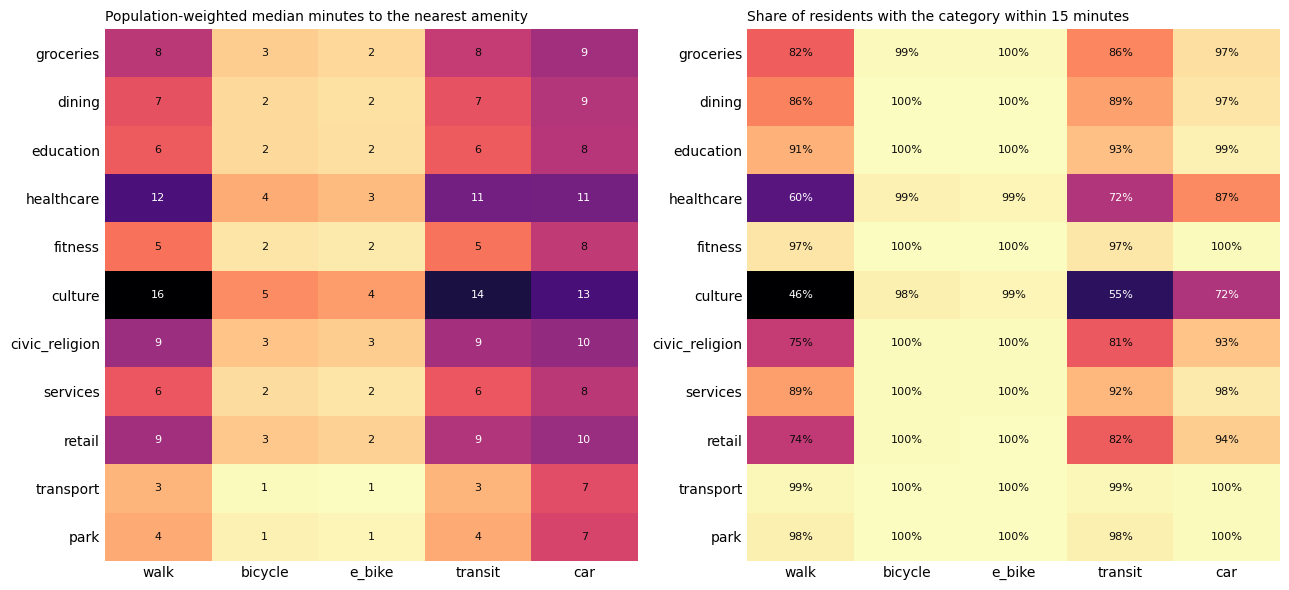

In [7]:
MODE_COLOURS = {"walk": "#2a78d6", "bicycle": "#1baf7a", "e_bike": "#7a4fbf", "transit": "#eb6834", "car": "#eda100"}

nearest_category["population"] = nearest_category["id"].map(population)
median_minutes = (
    nearest_category.groupby(["category", "mode"], observed=True)[["nearest_min", "population"]]
    .apply(lambda part: weighted_median(part["nearest_min"], part["population"]))
    .unstack("mode")
)
share_within = (
    nearest_category.assign(hit=(nearest_category["nearest_min"] <= PARAMETERS["score_budget_min"]) * nearest_category["population"])
    .groupby(["category", "mode"], observed=True)[["hit", "population"]]
    .apply(lambda part: part["hit"].sum() / part["population"].sum())
    .unstack("mode")
)

figure, axes = plt.subplots(ncols=2, figsize=(13, 6))
for axis, table, title, fmt, cmap in [
    (axes[0], median_minutes, "Population-weighted median minutes to the nearest amenity", "{:.0f}", "magma_r"),
    (axes[1], share_within, "Share of residents with the category within 15 minutes", "{:.0%}", "magma"),
]:
    image = axis.imshow(table.to_numpy(dtype=float), cmap=cmap, aspect="auto")
    axis.set_xticks(range(len(table.columns)), table.columns)
    axis.set_yticks(range(len(table.index)), table.index)
    axis.set_title(title, fontsize=10, loc="left")
    values = table.to_numpy(dtype=float)
    normed = (values - np.nanmin(values)) / (np.nanmax(values) - np.nanmin(values))
    for row in range(values.shape[0]):
        for column in range(values.shape[1]):
            light = normed[row, column] < 0.5 if cmap == "magma_r" else normed[row, column] > 0.5
            axis.text(column, row, fmt.format(values[row, column]), ha="center", va="center",
                      fontsize=8, color="#0b0b0b" if light else "#ffffff")
    axis.tick_params(length=0)
    for spine in axis.spines.values():
        spine.set_visible(False)
figure.tight_layout()

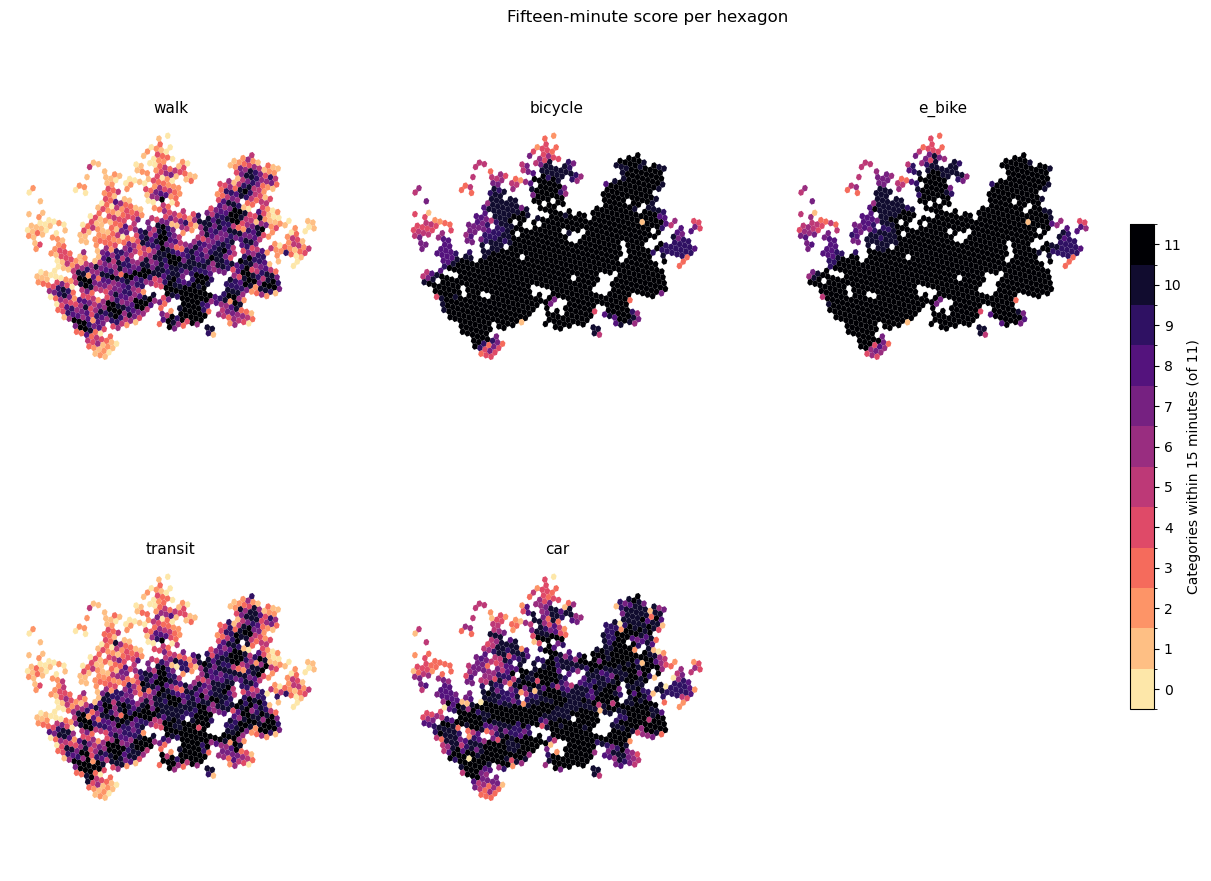

In [8]:
lattice_metric = lattice.to_crs(METRIC_CRS).set_index("id")
levels = np.arange(len(CATEGORIES) + 2) - 0.5
cmap = ListedColormap(plt.get_cmap("magma_r")(np.linspace(0.05, 1.0, len(CATEGORIES) + 1)))
norm = BoundaryNorm(levels, cmap.N)

figure, axes = plt.subplots(nrows=2, ncols=3, figsize=(17, 10.5))
for axis in axes.ravel()[len(MODES):]:
    axis.set_axis_off()
for axis, mode in zip(axes.ravel(), MODES):
    values = score.loc[score["mode"] == mode].set_index("id")["categories_within"]
    frame = lattice_metric.assign(score=values)
    frame.plot(ax=axis, column="score", cmap=cmap, norm=norm, linewidth=0)
    axis.set_title(mode, fontsize=11)
    axis.set_axis_off()
colourbar = figure.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=axes.ravel().tolist(), shrink=0.6, pad=0.02,
                            ticks=range(len(CATEGORIES) + 1))
colourbar.set_label(f"Categories within {PARAMETERS['score_budget_min']} minutes (of {len(CATEGORIES)})")
figure.suptitle("Fifteen-minute score per hexagon", y=0.93);

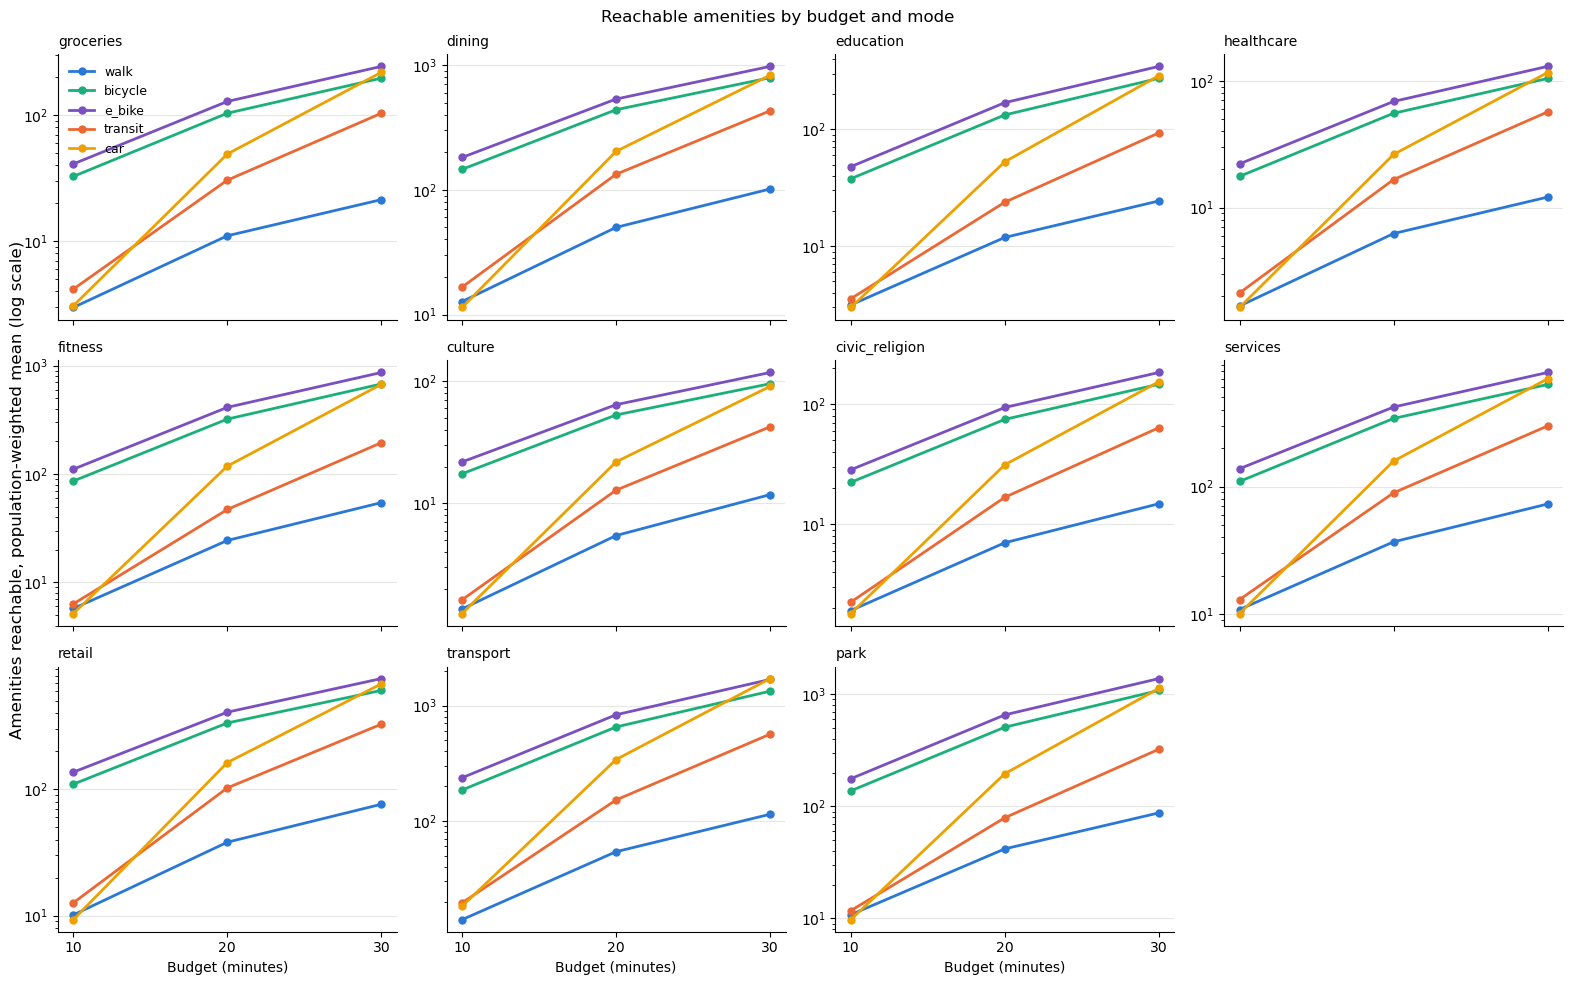

In [9]:
reachable_mean = (
    reachable.assign(weighted=reachable["amenities"] * reachable["population"])
    .groupby(["category", "budget", "mode"], observed=True)[["weighted", "population"]]
    .apply(lambda part: part["weighted"].sum() / part["population"].sum())
    .rename("amenities").reset_index()
)

figure, axes = plt.subplots(nrows=3, ncols=4, figsize=(16, 10), sharex=True)
for axis, category in zip(axes.ravel(), CATEGORIES):
    part = reachable_mean.loc[reachable_mean["category"] == category]
    for mode in MODES:
        series = part.loc[part["mode"] == mode].sort_values("budget")
        axis.plot(series["budget"], series["amenities"], color=MODE_COLOURS[mode], linewidth=2,
                  marker="o", markersize=5, label=mode)
    axis.set_yscale("log")
    axis.set_title(category, fontsize=10, loc="left")
    axis.set_xticks(PARAMETERS["budgets_min"])
    axis.grid(axis="y", color="#e6e6e3", linewidth=0.8)
    axis.spines[["top", "right"]].set_visible(False)
axes[-1, -1].set_axis_off()
axes[0, 0].legend(frameon=False, fontsize=9, loc="upper left")
for axis in axes[-1, :-1]:
    axis.set_xlabel("Budget (minutes)")
figure.supylabel("Amenities reachable, population-weighted mean (log scale)")
figure.suptitle("Reachable amenities by budget and mode")
figure.tight_layout()

### Share of the amenities reachable

The counts above depend on the stock of each category: dining has thousands of
points, culture a few hundred. Dividing each count by the number of points in
its category gives the share of the city's supply a household reaches, and the
overall index is the mean of the category shares, so every category weighs the
same whatever its size. The curves read as survival curves: the share of
residents reaching at least a given share of the amenities, one curve per mode
with the same budget, and the heatmap summarises them by their
population-weighted median.


In [10]:
# Share of the city's amenities reachable, per category and overall. Dividing
# by the stock of each category puts groceries and dining on the same footing;
# the overall index is the unweighted mean of the category shares, so a
# category with few points counts as much as one with many.
points_per_category = one_hot.sum()
share = reachable.assign(share=reachable["amenities"] / reachable["category"].map(points_per_category).astype(float))
share_all = (
    share.groupby(["id", "mode", "budget"], observed=True)["share"].mean()
    .rename("share").reset_index().assign(category="all")
)
share = pd.concat([share[share_all.columns], share_all], ignore_index=True)
share["population"] = share["id"].map(population)
SHARE_PANELS = ["all"] + CATEGORIES


from matplotlib.ticker import PercentFormatter


def share_ceiling(part):
    '''The axis limit for a set of shares: the maximum rounded up to the next 10%.'''
    return np.ceil(part["share"].max() * 10 + 0.5) / 10


def weighted_survival(values, weights):
    '''Share of the population at or above each value, as a step curve.'''
    order = np.argsort(values.to_numpy())
    values, weights = values.to_numpy()[order], weights.to_numpy()[order]
    above = 1 - (np.cumsum(weights) - weights) / weights.sum()
    return np.concatenate([[0.0], values]), np.concatenate([[1.0], above])


median_share = (
    share.groupby(["category", "budget", "mode"], observed=True)[["share", "population"]]
    .apply(lambda part: weighted_median(part["share"], part["population"]))
    .unstack("mode").reindex(SHARE_PANELS, level="category")
)
median_share.loc["all"].style.format("{:.1%}").set_caption("Population-weighted median share of amenities reachable, all categories")

mode,walk,bicycle,e_bike,transit,car
budget,,,,,
10.000000,0.1%,2.1%,2.6%,0.1%,0.1%
20.000000,0.5%,7.7%,10.0%,1.4%,3.2%
30.000000,1.2%,16.3%,21.3%,5.5%,20.5%


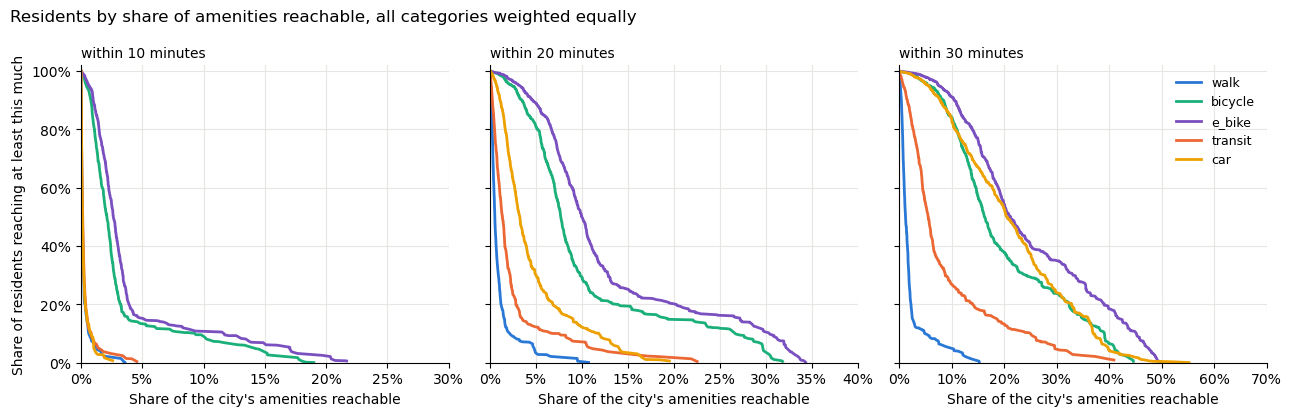

In [11]:
figure, axes = plt.subplots(ncols=len(PARAMETERS["budgets_min"]), figsize=(13, 4.2), sharey=True)
for axis, budget in zip(axes, PARAMETERS["budgets_min"]):
    part = share.loc[(share["category"] == "all") & (share["budget"] == budget)]
    for mode in MODES:
        rows = part.loc[part["mode"] == mode]
        x, y = weighted_survival(rows["share"], rows["population"])
        axis.plot(x, y, color=MODE_COLOURS[mode], linewidth=2, label=mode, solid_joinstyle="round")
    axis.set_title(f"within {budget} minutes", fontsize=10, loc="left")
    axis.set_xlim(0, share_ceiling(part))
    axis.set_ylim(0, 1.02)
    axis.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    axis.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    axis.grid(color="#e6e6e3", linewidth=0.8)
    axis.spines[["top", "right"]].set_visible(False)
    axis.set_xlabel("Share of the city's amenities reachable")
axes[0].set_ylabel("Share of residents reaching at least this much")
axes[-1].legend(frameon=False, fontsize=9, loc="upper right")
figure.suptitle("Residents by share of amenities reachable, all categories weighted equally", x=0.01, ha="left")
figure.tight_layout()

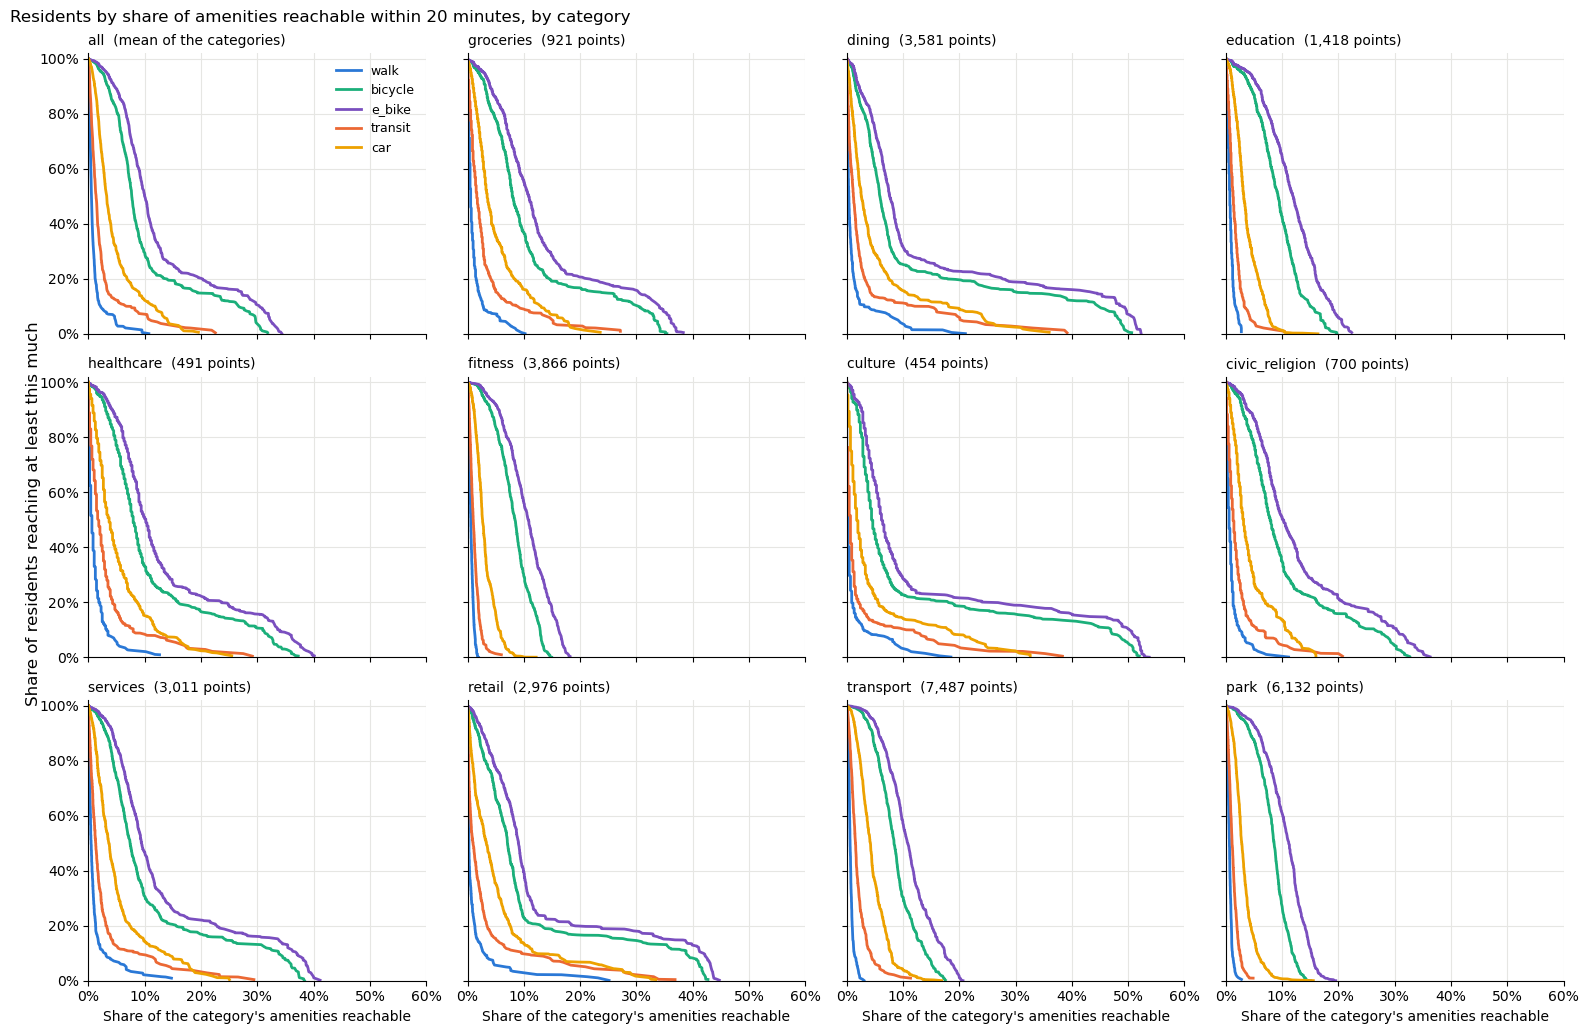

In [12]:
DISTRIBUTION_BUDGET = 20

at_budget = share.loc[share["budget"] == DISTRIBUTION_BUDGET]
figure, axes = plt.subplots(nrows=3, ncols=4, figsize=(16, 10.5), sharex=True, sharey=True)
for axis, category in zip(axes.ravel(), SHARE_PANELS):
    part = at_budget.loc[at_budget["category"] == category]
    for mode in MODES:
        rows = part.loc[part["mode"] == mode]
        x, y = weighted_survival(rows["share"], rows["population"])
        axis.plot(x, y, color=MODE_COLOURS[mode], linewidth=2, label=mode, solid_joinstyle="round")
    stock = "mean of the categories" if category == "all" else f"{points_per_category[category]:,} points"
    axis.set_title(f"{category}  ({stock})", fontsize=10, loc="left")
    axis.set_xlim(0, share_ceiling(at_budget))
    axis.set_ylim(0, 1.02)
    axis.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    axis.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    axis.grid(color="#e6e6e3", linewidth=0.8)
    axis.spines[["top", "right"]].set_visible(False)
axes[0, 0].legend(frameon=False, fontsize=9, loc="upper right")
for axis in axes[-1, :]:
    axis.set_xlabel("Share of the category's amenities reachable")
figure.supylabel("Share of residents reaching at least this much")
figure.suptitle(f"Residents by share of amenities reachable within {DISTRIBUTION_BUDGET} minutes, by category", x=0.01, ha="left")
figure.tight_layout()

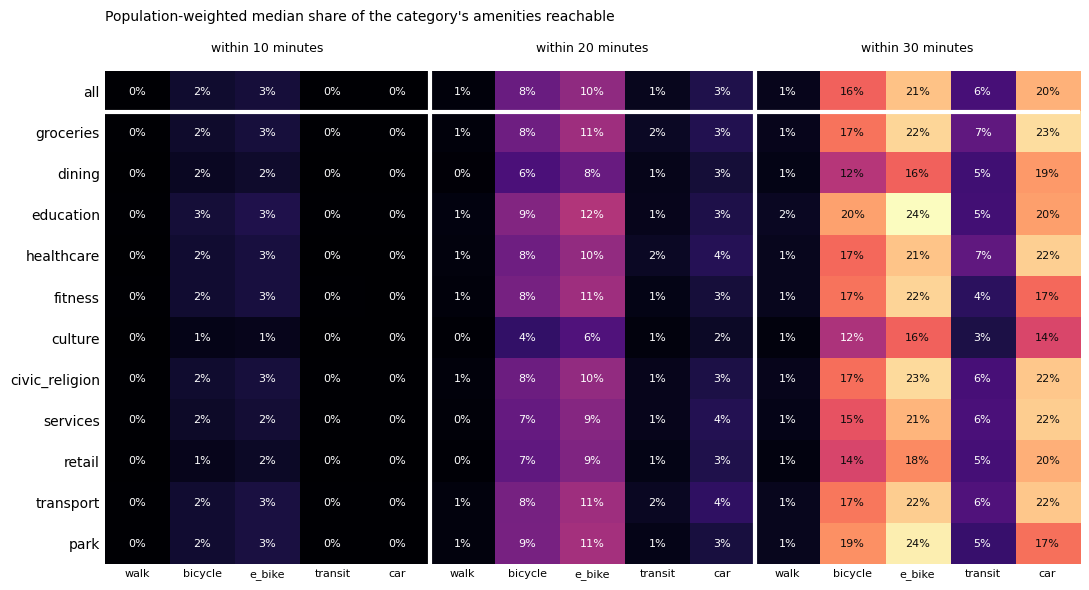

In [13]:
table = median_share.stack("mode").unstack(["budget", "mode"]).reindex(SHARE_PANELS)
table = table.reindex(columns=pd.MultiIndex.from_product([PARAMETERS["budgets_min"], MODES]))
values = table.to_numpy(dtype=float)
n_modes = len(MODES)

figure, axis = plt.subplots(figsize=(11, 6))
axis.imshow(values, cmap="magma", vmin=0, vmax=np.nanmax(values), aspect="auto")
axis.set_xticks(range(values.shape[1]), [mode for _, mode in table.columns], fontsize=8)
axis.set_yticks(range(values.shape[0]), table.index)
for position, budget in enumerate(PARAMETERS["budgets_min"]):
    axis.text(position * n_modes + (n_modes - 1) / 2, -0.9, f"within {budget} minutes", ha="center", va="bottom", fontsize=9)
for column in range(n_modes, values.shape[1], n_modes):
    axis.axvline(column - 0.5, color="#ffffff", linewidth=3)
axis.axhline(0.5, color="#ffffff", linewidth=3)
threshold = np.nanmax(values) / 2
for row in range(values.shape[0]):
    for column in range(values.shape[1]):
        axis.text(column, row, f"{values[row, column]:.0%}", ha="center", va="center", fontsize=8,
                  color="#0b0b0b" if values[row, column] > threshold else "#ffffff")
axis.tick_params(length=0)
for spine in axis.spines.values():
    spine.set_visible(False)
axis.set_title("Population-weighted median share of the category's amenities reachable", fontsize=10, loc="left", pad=36)
figure.tight_layout()

## Next

- The carbon side: which categories a household reaches within budget only by
  car, and the emissions those trips carry at each fleet state.
- The soft score (logistic decay around the budget) as a sensitivity on the
  step counts; a transit departure window with the median instead of the
  single departure.
- The gravity measure over population with one shared decay, for the
  carbon-gap weighting.